# Tutorial for the YamboScreeningParser class

This tutorial describes the `YamboScreeningParser` class, which reads the screening databases written by Yambo
(`ndb.em1s` for the static screening, `ndb.em1d` for many frequencies and `ndb.pp` for the plasmon pole
approximation, each with its fragments `ndb.<kind>_fragment_<iq>`). For each q point of the IBZ and each frequency
the databases contain the symmetrized matrix

$$X_{\mathbf{G}\mathbf{G}'}(\mathbf{q},\omega) = v^{1/2}_\mathbf{G}(\mathbf{q})\,\chi_{\mathbf{G}\mathbf{G}'}(\mathbf{q},\omega)\,
v^{1/2}_{\mathbf{G}'}(\mathbf{q}) = \epsilon^{-1}_{\mathbf{G}\mathbf{G}'}(\mathbf{q},\omega) - \delta_{\mathbf{G}\mathbf{G}'} ,$$

where $\chi$ is the reducible response function and $v_\mathbf{G}(\mathbf{q}) = 4\pi/|\mathbf{q}+\mathbf{G}|^2$ the
Coulomb interaction (cut, if the run uses a Coulomb cutoff: then it is read from the `ndb.cutoff` database). The class
computes the quantities derived from X, transforms X under a rotation and a translation of the system and writes a new
database with a modified X, which Yambo can then use (e.g. in a GW computation).

We use the database of the GW computation (plasmon pole) of silicon done in the YamboCalculator tutorial, in the folder
`Yambo_tutorial/gw_ppa`. The files written in this tutorial go in the `YamboScreeningParser_tutorial` folder.

In [1]:
# useful to autoreload the module without restarting the kernel
%load_ext autoreload
%autoreload 2

import os, shutil, datetime
import numpy as np
import matplotlib.pyplot as plt
from mppi.Parsers import YamboScreeningParser

print('Notebook executed on', datetime.datetime.now().strftime('%d/%m/%Y %H:%M'))

Notebook executed on 18/11/2026 12:02


## Reading the database

The object is built from the folder of the database and from the `SAVE` folder of the computation, which gives the
lattice and the lattice parameters used by Yambo for the G vectors and the q points. The folder must contain only one of
the three kinds of database. Without Coulomb cutoff (as here) no other file is needed; with a cutoff, the path of the
`ndb.cutoff` database of the run is passed with the `cutoff` argument.

In [2]:
scr = YamboScreeningParser('Yambo_tutorial/gw_ppa', 'Yambo_tutorial/SAVE')

Screening database Yambo_tutorial/gw_ppa/ndb.pp
number of q points 32 - number of G vectors 27 - bands 1-8 - kernel HARTREE - cutoff none
frequencies (eV): [0. +0.j     0.+27.2114j]


The G vectors are given in cartesian coordinates (bohr$^{-1}$) and as Miller indices, the q points of the IBZ in
cartesian and crystal coordinates. The first q point is $\mathbf{q} = 0$: Yambo computes it at the small vector
$\mathbf{q}_0$ (the field direction of the database), used by the class for the Coulomb interaction of $\mathbf{G} = 0$
and, through its direction, in the symmetry transformations.

In [3]:
print('kind:', scr.kind, '- ng:', scr.ng, '- nq:', scr.nq, '- bands:', scr.bands)
print('q0 (bohr^-1):', scr.q0)
print('first G vectors (Miller indices):', scr.G_crystal[:5].tolist())
print('q points 1-4 (crystal):', np.round(scr.q_crystal[:4], 4).tolist())

kind: pp - ng: 27 - nq: 32 - bands: (1, 8)
q0 (bohr^-1): [9.99999975e-06 0.00000000e+00 0.00000000e+00]
first G vectors (Miller indices): [[0, 0, 0], [-1, -1, -1], [-1, 0, 0], [0, -1, 0], [0, 0, -1]]
q points 1-4 (crystal): [[0.0, 0.0, 0.0], [0.0, 0.0, 0.1667], [0.0, 0.0, 0.3333], [0.0, 0.0, -0.5]]


The matrices are read, one q point at a time, by `get_X(iq)` (q points numbered from 1, as in the names of the
fragments): a complex array with shape (frequencies, ng, ng) and order $[\omega, \mathbf{G}, \mathbf{G}']$. With the
plasmon pole the two frequencies are 0 and $i\,27.2$ eV; on the imaginary axis X is Hermitian (within the single
precision of the database).

In [4]:
herm = 0
for iq in range(1, scr.nq + 1):
    X = scr.get_X(iq)
    herm = max(herm, np.abs(X - np.conj(np.swapaxes(X, 1, 2))).max())
print('shape of X:', X.shape)
print('max |X - X^dagger| over all the q points and both frequencies: %.1e' % herm)

shape of X: (2, 27, 27)
max |X - X^dagger| over all the q points and both frequencies: 3.6e-07


## Quantities derived from X

`eps_inv` gives $\epsilon^{-1} = 1 + X$; `chi0` the symmetrized independent particle response function
$\tilde\chi_0 = v^{1/2}\chi_0 v^{1/2} = 1 - (1+X)^{-1}$, obtained by inverting the Dyson equation of the RPA (only for
the 'HARTREE' kernel) in the block of the database; `coulomb` the interaction $v_\mathbf{G}(\mathbf{q})$, `W` the screened
interaction $W = v^{1/2}(1+X)v^{1/2}$ and `chi` the reducible response $\chi = v^{-1/2}Xv^{-1/2}$. All these methods
accept a matrix X as optional argument, to work on a matrix built by the user instead of the one of the database.

The head of $\epsilon^{-1}$ at $\mathbf{q}\to 0$ gives the macroscopic dielectric constant with local fields,
$\epsilon_M = 1/\epsilon^{-1}_{00}$ (here far from convergence: 27 G vectors and 8 bands).

static epsilon_M at q -> 0: 15.617
Dyson round trip at iq = 5, max |dX|: 3.4e-16


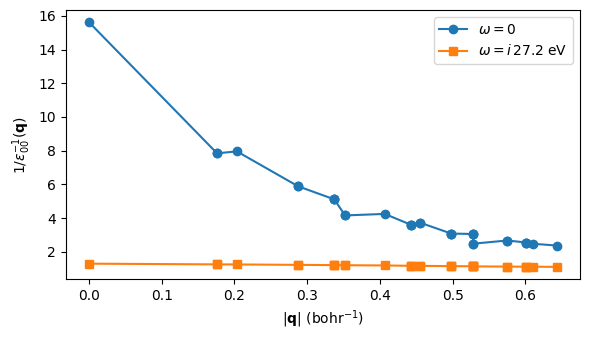

In [5]:
eps_inv = scr.eps_inv(1)
print('static epsilon_M at q -> 0: %.3f' % (1 / eps_inv[0, 0, 0].real))

# chi0 recovered from X gives X back through the Dyson equation X = (1 - chi0)^-1 chi0
I = np.eye(scr.ng)
c0 = scr.chi0(5)
print('Dyson round trip at iq = 5, max |dX|: %.1e' % np.abs(np.linalg.solve(I - c0, c0) - scr.get_X(5)).max())

# head of 1/eps^-1 and of W/v as a function of |q|
qn = np.linalg.norm(scr.q, axis=1)
qn[0] = np.linalg.norm(scr.q0)
head = np.array([scr.eps_inv(iq)[:, 0, 0].real for iq in range(1, scr.nq + 1)])
order = np.argsort(qn)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(qn[order], 1 / head[order, 0], 'o-', label=r'$\omega = 0$')
ax.plot(qn[order], 1 / head[order, 1], 's-', label=r'$\omega = i\,27.2$ eV')
ax.set_xlabel(r'$|\mathbf{q}|$ (bohr$^{-1}$)')
ax.set_ylabel(r'$1/\epsilon^{-1}_{00}(\mathbf{q})$')
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
v = scr.coulomb(2)
W = scr.W(2)
print('v_G(q) of the first G at iq = 2 (Ha bohr^3):', np.round(v[:3], 4))
print('W/v at G = G\' = 0, iq = 2: w = 0 %.4f, w = i 27 eV %.4f' % tuple((W[:, 0, 0] / v[0]).real))

v_G(q) of the first G at iq = 2 (Ha bohr^3): [405.234   12.2798   9.8838]
W/v at G = G' = 0, iq = 2: w = 0 0.1274, w = i 27 eV 0.7914


## Symmetry transformations

`transform(X, iq, rotation, translation)` gives the X of the system moved by $\mathbf{r}\to R\mathbf{r}+\boldsymbol{\tau}$:

$$X'_{\mathbf{G}\mathbf{G}'}(\mathbf{q}) = e^{-i(\mathbf{G}-\mathbf{G}')\cdot\boldsymbol{\tau}}\,
X_{R^{-1}\mathbf{G},R^{-1}\mathbf{G}'}(R^{-1}\mathbf{q}) .$$

Only the operations with $R^{-1}\mathbf{q} = \pm\mathbf{q}$ are implemented (for $-\mathbf{q}$ the time reversal relation
$X_{\mathbf{G}\mathbf{G}'}(-\mathbf{q}) = X_{-\mathbf{G}',-\mathbf{G}}(\mathbf{q})$ is used; at $\mathbf{q} = 0$ the
direction of $\mathbf{q}_0$). The class checks that the G set is closed under R and that R leaves the (cut) Coulomb
interaction invariant. The rotation is a cartesian orthogonal matrix, the translation is in bohr.

A symmetry operation of the crystal must give X back. We apply all the operations of the `SAVE` (the attribute `syms`
contains the cartesian matrices that Yambo applies to the k points) to every q point, when they map q onto $\pm$q.

In [7]:
ndirect = nreversal = 0
dev = 0
for iq in range(1, scr.nq + 1):
    X = scr.get_X(iq)
    qv = scr.q0 if iq == 1 else scr.q[iq - 1]
    for R in scr.syms:
        try:
            Xt = scr.transform(X, iq, rotation=R)
        except NotImplementedError:          # R^-1 q is not +-q
            continue
        if np.allclose(R.T @ qv, qv, atol=1e-6):
            ndirect += 1
        else:
            nreversal += 1
        dev = max(dev, np.abs(Xt - X).max() / np.abs(X).max())
print('%d operations with R^-1 q = q, %d with R^-1 q = -q: max |X\' - X| / max |X| = %.1e' % (ndirect, nreversal, dev))

66 operations with R^-1 q = q, 66 with R^-1 q = -q: max |X' - X| / max |X| = 6.4e-07


A translation by a lattice vector gives X back. The two Si atoms of this cell are at $\\pm\\mathbf{p}$, so the
origin is the center of the bond and the inversion $\\mathbf{r}\\to-\\mathbf{r}$ (an operation of the `SAVE`) exchanges
them. On the contrary, the translation from one atom to the other one and the inversion about one atom
($R = -1$, $\\boldsymbol{\\tau} = 2\\mathbf{p}$) are not symmetries of the diamond structure and change X.

In [8]:
from mppi.Parsers import YamboDftParser
atoms = [np.array(pos, dtype=float) for name, pos in YamboDftParser('Yambo_tutorial/SAVE/ns.db1', verbose=False).atomic_positions]
print('atomic positions (bohr):', [np.round(a, 4).tolist() for a in atoms])
X3 = scr.get_X(3)
tau = atoms[1] - atoms[0]
inversion = -np.eye(3)
rel = lambda A, B: np.linalg.norm(A - B) / np.linalg.norm(B)
print('lattice translation:            ||X\' - X|| / ||X|| = %.1e' % rel(scr.transform(X3, 3, translation=scr.lattice[0]), X3))
print('inversion about the bond center: ||X\' - X|| / ||X|| = %.1e' % rel(scr.transform(X3, 3, rotation=inversion), X3))
print('translation from atom 1 to 2:   ||X\' - X|| / ||X|| = %.2f' % rel(scr.transform(X3, 3, translation=tau), X3))
print('inversion about atom 1:         ||X\' - X|| / ||X|| = %.2f' % rel(
      scr.transform(X3, 3, rotation=inversion, translation=2 * atoms[0]), X3))

atomic positions (bohr): [[-1.2875, 1.2875, 1.2875], [1.2875, -1.2875, -1.2875]]
lattice translation:            ||X' - X|| / ||X|| = 8.7e-17
inversion about the bond center: ||X' - X|| / ||X|| = 1.3e-06
translation from atom 1 to 2:   ||X' - X|| / ||X|| = 0.54
inversion about atom 1:         ||X' - X|| / ||X|| = 0.54


## Writing a new database

`write(dst, X)` writes a new database in the folder `dst`, with the database of the object as template: it copies the
header and all the fragments (only the `ndb.<kind>*` files) and replaces the matrices of the given q points (X is a
dictionary iq $\to$ matrix, or a function of iq). The X of the other q points is the one of the template. A fragment
that already exists in `dst` is rewritten only if its X differs by more than a tolerance, and every matrix written is
read back and checked. The header (bands, number of G vectors, cutoff, frequencies) stays the one of the template, so
Yambo assumes the parameters of the template.

Some precautions: `dst` cannot be the folder of the template, a folder with a database with a different header is
refused unless `overwrite=True`, and the `ndb.RIM_W` database is never copied (Yambo builds it from X and reuses a file
with a matching header without checking X: a database with a modified X must never carry an old `ndb.RIM_W`, a folder
that contains one is refused unless `overwrite=True`, which removes it).

As an example we write, at all the q points, the X of the crystal translated by $\boldsymbol{\tau}$ (from one atom
to the other one).

In [9]:
out = 'YamboScreeningParser_tutorial'
if os.path.isdir(out):
    shutil.rmtree(out)
dst = os.path.join(out, 'gw_ppa_translated')
moved = lambda iq: scr.transform(scr.get_X(iq), iq, translation=tau)
summary = scr.write(dst, moved)

Database written in YamboScreeningParser_tutorial/gw_ppa_translated: X written at 32 q points, 0 fragments copied from the template, 0 unchanged


In [10]:
new = YamboScreeningParser(dst, 'Yambo_tutorial/SAVE', verbose=False)
err = max(np.abs(new.get_X(iq) - moved(iq)).max() for iq in range(1, scr.nq + 1))
print('database read back, max |X_read - X| = %.1e' % err)
print('files of the new folder:', len(os.listdir(dst)), '- ndb.RIM_W present:', os.path.isfile(os.path.join(dst, 'ndb.RIM_W')))
# a second call does not rewrite the fragments that are already up to date
summary = scr.write(dst, moved)

database read back, max |X_read - X| = 3.0e-17
files of the new folder: 33 - ndb.RIM_W present: False


Database written in YamboScreeningParser_tutorial/gw_ppa_translated: X written at 0 q points, 0 fragments copied from the template, 32 unchanged


## Tools for 2D systems

For a 2D system (first two lattice vectors in the xy plane, third one along z, as in the `WfcParser` class) the
method `inplane_blocks()` groups the G vectors by their in-plane part $\mathbf{G}_\parallel$, `inplane_Q(iq, G_par)`
gives $\mathbf{Q} = \mathbf{q} + \mathbf{G}_\parallel$ and `planar(M, iq, G_par, z, z2)` gives the mixed representation of
a matrix M (X, W, $\chi$, ...) on the block $\mathbf{G}_\parallel = \mathbf{G}'_\parallel$:

$$M(\mathbf{Q}; z, z') = \frac{1}{c}\sum_{G_z, G_z'} e^{iG_z z} M_{\mathbf{G}\mathbf{G}'} e^{-iG_z' z'} ,$$

so that, for instance, the slab-cut Coulomb interaction gives $v(\mathbf{Q}; z, z') = (2\pi/Q)e^{-Q|z-z'|}$ for
$|z-z'| < c/2$. Silicon is not a 2D system, so these methods raise an error here; they are tested on synthetic databases
in `tests/test_screeningparser.py`.

In [11]:
try:
    scr.inplane_blocks()
except ValueError as e:
    print('ValueError:', e)

ValueError: The methods for 2D systems need the first two lattice vectors in the xy plane and the third one along z
